In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

CSV_PATH = glob.glob("/kaggle/input/**/*.csv", recursive=True)[0]
TARGET = "Purchased"   # عدّله إذا اسم عمود الهدف مختلف
EPOCHS = 200
LR = 0.1
BATCH_SIZE = 32
SEED = 42

df = pd.read_csv(CSV_PATH).dropna()
print(df.columns.tolist())
df.head()

['Customer id', 'Age', 'Gender', 'Location', 'Email Opened', 'Email Clicked', 'Product page visit', 'Discount offered', 'Purchased']


,Customer id,Age,Gender,Location,Email Opened,Email Clicked,Product page visit,Discount offered,Purchased
0,1,22,0,Perth,1,1,3,1,1
1,2,55,0,Auckland,1,0,0,0,0
2,3,15,1,Sydney,0,1,2,1,1
3,4,25,0,Brisbane,1,1,5,1,0
4,5,36,1,Brisbane,0,1,1,1,0


In [2]:
if TARGET not in df.columns:
    TARGET = df.columns[-1]
    print("Using last column as target:", TARGET)

y = df[TARGET].astype(int).values
X = pd.get_dummies(df.drop(columns=[TARGET]), drop_first=True).astype(float).values

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(X))
split = int(0.8 * len(X))
tr, te = idx[:split], idx[split:]
X_train, X_test, y_train, y_test = X[tr], X[te], y[tr], y[te]

mu, sd = X_train.mean(0), X_train.std(0)
sd[sd == 0] = 1
X_train = (X_train - mu) / sd
X_test = (X_test - mu) / sd

X_train = np.c_[np.ones(len(X_train)), X_train]
X_test = np.c_[np.ones(len(X_test)), X_test]
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16, 11) Test: (4, 11)


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def bce_loss(y, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradient(X, y, w):
    return X.T @ (sigmoid(X @ w) - y) / len(y)

def metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return acc, prec, rec, f1

In [4]:
OPT_NAME = "Adam"
ADAM_LR = 0.01
b1, b2, eps = 0.9, 0.999, 1e-8
w = np.zeros(X_train.shape[1])
m = np.zeros_like(w)
s = np.zeros_like(w)
t = 0
history = []
n = len(y_train)

for epoch in range(EPOCHS):
    p = rng.permutation(n)
    for i in range(0, n, BATCH_SIZE):
        b = p[i:i + BATCH_SIZE]
        g = gradient(X_train[b], y_train[b], w)
        t += 1
        m = b1 * m + (1 - b1) * g
        s = b2 * s + (1 - b2) * g ** 2
        m_hat = m / (1 - b1 ** t)
        s_hat = s / (1 - b2 ** t)
        w -= ADAM_LR * m_hat / (np.sqrt(s_hat) + eps)
    history.append(bce_loss(y_train, sigmoid(X_train @ w)))

=== Adam ===
Accuracy : 0.2500
Precision: 0.0000
Recall   : 0.0000
F1-score : 0.0000
Loss     : 2.1451


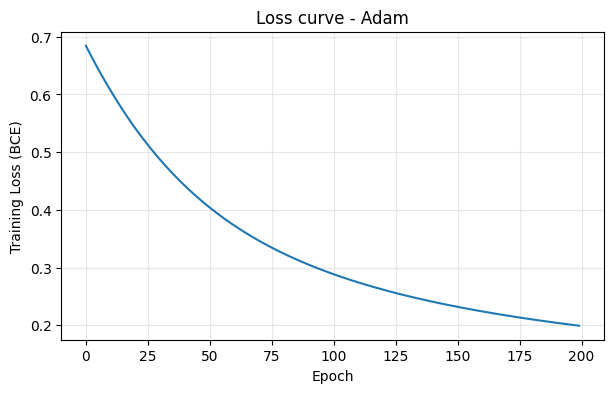

In [5]:
p_test = sigmoid(X_test @ w)
pred = (p_test >= 0.5).astype(int)
acc, prec, rec, f1 = metrics(y_test, pred)
test_loss = bce_loss(y_test, p_test)

print(f"=== {OPT_NAME} ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"Loss     : {test_loss:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Training Loss (BCE)")
plt.title(f"Loss curve - {OPT_NAME}")
plt.grid(alpha=0.3)
plt.show()